# 02 Population: where potential visitors live

**Data.** Kontur Population (HDX, CC BY 4.0) estimates the number of residents in 400 m hexagons of the H3 grid, built from satellite settlement data (GHSL), Facebook population maps and OpenStreetMap. One country file covers all of Russia, so we read only the part we need.

**Study area.** The market is residents of St Petersburg and Leningrad Oblast travelling by car, plus the parts of Pskov and Novgorod oblasts within `BORDER_KM` of the Leningrad Oblast border. Region boundaries come from OpenStreetMap (© OpenStreetMap contributors) via osmnx.

**CRS.** Raw data is in degrees. Distances, buffers and grid cells are computed in UTM zone 36N (EPSG:32636), a projection in metres suited to north-west Russia.

**Origins.** 400 m hexagons are too many for a travel time matrix, so they are summed into coarse cells of `CELL_KM` km. Each cell becomes one origin, placed at its population-weighted centre.

In [1]:
import os, glob, gzip, shutil
import pandas as pd
import geopandas as gpd
import pyogrio
import osmnx as ox
import matplotlib.pyplot as plt

RAW = "../data/raw"
PROCESSED = "../data/processed"

CRS_M = "EPSG:32636"   # UTM zone 36N, metres
BORDER_KM = 50         # reach into Pskov and Novgorod oblasts
CELL_KM = 5            # size of the coarse origin cells

In [2]:
# Unpack .gpkg.gz -> .gpkg once (a GeoPackage must be unpacked to be read quickly)
gpkg_files = glob.glob(os.path.join(RAW, "kontur_population_RU_*.gpkg"))
gz_files = glob.glob(os.path.join(RAW, "kontur_population_RU_*.gpkg.gz"))

if not gpkg_files:
    if not gz_files:
        raise FileNotFoundError("Put kontur_population_RU_*.gpkg.gz into data/raw first")
    src = gz_files[0]
    dst = src[:-3]
    print("Unpacking", src, "(takes a minute or two)")
    with gzip.open(src, "rb") as f_in, open(dst, "wb") as f_out:
        shutil.copyfileobj(f_in, f_out)
    gpkg_files = [dst]

KONTUR = gpkg_files[0]
print(KONTUR, round(os.path.getsize(KONTUR) / 1e6), "MB")

# Look inside without loading: CRS, number of hexagons, column names
info = pyogrio.read_info(KONTUR)
print("CRS:", info["crs"])
print("Hexagons:", info["features"])
print("Columns:", list(info["fields"]))

Unpacking ../data/raw\kontur_population_RU_20231101.gpkg.gz (takes a minute or two)
../data/raw\kontur_population_RU_20231101.gpkg 181 MB
CRS: EPSG:3857
Hexagons: 926647
Columns: ['h3', 'population']


                          region  area_km2
0               Saint Petersburg    2284.0
1               Leningrad Oblast   94868.0
2     Pskov Oblast (border part)    8357.0
3  Novgorod Oblast (border part)   20019.0


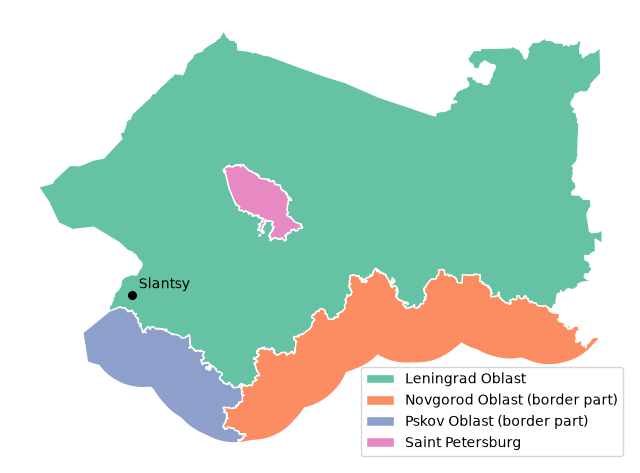

In [3]:
# Region boundaries from OpenStreetMap, cached in data/raw
REGIONS = {
    "Saint Petersburg": "Санкт-Петербург, Россия",
    "Leningrad Oblast": "Ленинградская область, Россия",
    "Pskov Oblast": "Псковская область, Россия",
    "Novgorod Oblast": "Новгородская область, Россия",
}
regions_path = os.path.join(RAW, "regions_osm.geojson")

if os.path.exists(regions_path):
    regions = gpd.read_file(regions_path)
else:
    parts = [ox.geocode_to_gdf(q)[["geometry"]].assign(region=name) for name, q in REGIONS.items()]
    regions = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), crs="EPSG:4326")
    regions.to_file(regions_path, driver="GeoJSON")

# Work in metres
reg = regions.to_crs(CRS_M).set_index("region")["geometry"]
spb = reg["Saint Petersburg"]
lo = reg["Leningrad Oblast"].difference(spb)        # make sure SPb is not counted twice

# Border zone: everything within BORDER_KM of SPb + Leningrad Oblast
core = spb.union(lo).simplify(500)                  # simplify first so the buffer is fast
zone = core.buffer(BORDER_KM * 1000)
pskov = reg["Pskov Oblast"].intersection(zone)
novg = reg["Novgorod Oblast"].intersection(zone)

study = gpd.GeoDataFrame(
    {"region": ["Saint Petersburg", "Leningrad Oblast",
                "Pskov Oblast (border part)", "Novgorod Oblast (border part)"]},
    geometry=[spb, lo, pskov, novg], crs=CRS_M)
study["area_km2"] = (study.area / 1e6).round()
print(study[["region", "area_km2"]])

# Check map, Slantsy marked for orientation
slantsy = gpd.GeoSeries(gpd.points_from_xy([28.09], [59.12]), crs="EPSG:4326").to_crs(CRS_M)
ax = study.plot(column="region", cmap="Set2", edgecolor="white", legend=True,
                figsize=(8, 8), legend_kwds={"loc": "lower right"})
slantsy.plot(ax=ax, color="black", markersize=30)
ax.annotate("Slantsy", (slantsy.x[0], slantsy.y[0]), xytext=(5, 5), textcoords="offset points")
ax.set_axis_off()
plt.show()

In [4]:
# Read only the hexagons inside a box around the study area (uses the file's spatial index)
box = gpd.GeoSeries([study.union_all().envelope.buffer(10_000)], crs=CRS_M)
hexes = gpd.read_file(KONTUR, bbox=box).to_crs(CRS_M)
print("Hexagons in the box:", f"{len(hexes):,}")

# Assign each hexagon to a region by its centre point
centres = hexes.copy()
centres["geometry"] = hexes.centroid
centres = gpd.sjoin(centres, study[["region", "geometry"]], predicate="within", how="inner")
centres = centres.drop(columns="index_right")
print("Hexagons in the study area:", f"{len(centres):,}")

# Population by region vs official estimates (Petrostat, 1 March 2024)
OFFICIAL = {"Saint Petersburg": 5_598_000, "Leningrad Oblast": 2_037_100}
by_region = centres.groupby("region")["population"].sum().round().astype(int).to_frame("kontur")
by_region["official"] = pd.Series(OFFICIAL)
by_region["diff_pct"] = (by_region["kontur"] / by_region["official"] * 100 - 100).round(1)
print(by_region)
print("Total in study area:", f"{by_region['kontur'].sum():,}")

Hexagons in the box: 48,071
Hexagons in the study area: 34,766
                                kontur   official  diff_pct
region                                                     
Leningrad Oblast               2482708  2037100.0      21.9
Novgorod Oblast (border part)   350510        NaN       NaN
Pskov Oblast (border part)       55342        NaN       NaN
Saint Petersburg               5377239  5598000.0      -3.9
Total in study area: 8,265,799


## From hexagons to origins

**Population check.** Compared with official estimates (Petrostat, 1 March 2024), Kontur gives St Petersburg -3.9% and Leningrad Oblast +21.9% (both together +2.9%). Spot checks show the SPb suburbs are close (Vsevolozhsky district +2.7%) and Slantsy district moderately high (+11.6%), so the surplus most likely sits in the dacha belt: satellites see garden houses (*sadovodstva*) and Kontur counts their owners as permanent residents. We keep Kontur values unchanged: summer residents are real potential visitors in the main visiting season, and an overall level difference is absorbed by calibration. A version scaled to official totals is a sensitivity check for later.

**Aggregation.** Each hexagon centre is placed in a square grid cell of `CELL_KM` km (column = x // cell size, row = y // cell size, in metres). Populations are summed per cell and region, and the origin point is the population-weighted centre, so it sits where people actually live rather than in the middle of the cell. Cells on a region border are split, so every origin belongs to one region.

**Result.** 3,465 origins. About half have fewer than 100 residents (0.6% of the population together); they are kept, because travel times to all origins cost the same as to a few.

In [6]:
# Which coarse grid cell does each hexagon centre fall into?
size = CELL_KM * 1000
centres["x"] = centres.geometry.x
centres["y"] = centres.geometry.y
centres["col"] = (centres["x"] // size).astype(int)
centres["row"] = (centres["y"] // size).astype(int)

# Sum population per cell and region, with a population-weighted centre
centres["px"] = centres["x"] * centres["population"]
centres["py"] = centres["y"] * centres["population"]
origins = (centres.groupby(["region", "col", "row"])
           .agg(population=("population", "sum"), px=("px", "sum"),
                py=("py", "sum"), n_hex=("h3", "size"))
           .reset_index())
origins = origins[origins["population"] > 0].copy()
origins["x"] = origins["px"] / origins["population"]
origins["y"] = origins["py"] / origins["population"]
origins = origins.drop(columns=["px", "py"])

# Add lat/lon (handy for folium maps later) and an ID
pts = gpd.GeoSeries(gpd.points_from_xy(origins["x"], origins["y"]), crs=CRS_M).to_crs("EPSG:4326")
origins["lon"] = pts.x.round(5).values
origins["lat"] = pts.y.round(5).values
origins = origins.sort_values("population", ascending=False).reset_index(drop=True)
origins.insert(0, "origin_id", origins.index)

# Checks
print("Origins:", len(origins), "| population kept:", f"{origins['population'].sum():,.0f}",
      "of", f"{centres['population'].sum():,.0f}")
print(origins.groupby("region")["population"].agg(["size", "sum"]).round())
print("\nSmall origins (< 100 people):", (origins["population"] < 100).sum(),
      "holding", f"{origins.loc[origins['population'] < 100, 'population'].sum():,.0f}", "people")
print("\nLargest origins:")
print(origins.head(8)[["origin_id", "region", "population", "n_hex", "lat", "lon"]])

Origins: 3465 | population kept: 8,265,799 of 8,265,799
                               size        sum
region                                        
Leningrad Oblast               2434  2482708.0
Novgorod Oblast (border part)   633   350510.0
Pskov Oblast (border part)      291    55342.0
Saint Petersburg                107  5377239.0

Small origins (< 100 people): 1719 holding 46,565 people

Largest origins:
   origin_id            region  population  n_hex       lat       lon
0          0  Saint Petersburg    413595.0     40  60.02956  30.35367
1          1  Saint Petersburg    385049.0     40  59.84829  30.37387
2          2  Saint Petersburg    333164.0     39  59.84389  30.19592
3          3  Saint Petersburg    328370.0     39  59.93831  30.27390
4          4  Saint Petersburg    326125.0     40  59.93615  30.35696
5          5  Saint Petersburg    314877.0     40  59.93920  30.45650
6          6  Saint Petersburg    304771.0     40  59.84919  30.27414
7          7  Saint Peters

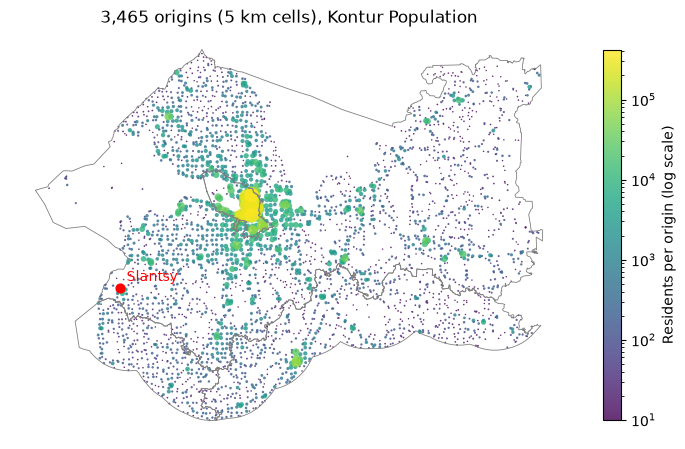

In [7]:
# Check map: one dot per origin, size and colour by population
from matplotlib.colors import LogNorm

o = origins.sort_values("population")          # big dots drawn last, on top
fig, ax = plt.subplots(figsize=(9, 8))
study.boundary.plot(ax=ax, color="grey", linewidth=0.6)
sc = ax.scatter(o["x"], o["y"], s=o["population"] ** 0.5 / 6 + 1,
                c=o["population"], cmap="viridis", norm=LogNorm(vmin=10, vmax=o["population"].max()),
                alpha=0.8, linewidths=0)
slantsy.plot(ax=ax, color="red", markersize=40)
ax.annotate("Slantsy", (slantsy.x[0], slantsy.y[0]), xytext=(5, 5), textcoords="offset points", color="red")
plt.colorbar(sc, ax=ax, shrink=0.6, label="Residents per origin (log scale)")
ax.set_title(f"{len(origins):,} origins ({CELL_KM} km cells), Kontur Population")
ax.set_axis_off()
plt.show()

In [8]:
# Save origins and the study area for the next notebooks
out = origins[["origin_id", "region", "population", "n_hex", "x", "y", "lat", "lon"]].copy()
out[["population", "x", "y"]] = out[["population", "x", "y"]].round(1)
out.to_csv(os.path.join(PROCESSED, "origins.csv"), index=False)

area_out = study.copy()
area_out["geometry"] = area_out.simplify(200)
area_out.to_crs("EPSG:4326").to_file(os.path.join(PROCESSED, "study_area.geojson"), driver="GeoJSON")

for f in ["origins.csv", "study_area.geojson"]:
    print(f, round(os.path.getsize(os.path.join(PROCESSED, f)) / 1e3), "KB")

origins.csv 245 KB
study_area.geojson 91 KB
